# Chapter 6: Statistical Machine Learning

This notebook reproduces the Python code from Chapter 6 of *Practical Statistics for Data Scientists* (2nd Edition) by Peter Bruce, Andrew Bruce, and Peter Gedeck.

Statistical machine learning refers to automated, data-driven prediction methods that do not assume a fixed overall structure (such as a straight line) for the data. This chapter covers K-Nearest Neighbors (KNN), decision trees, and ensemble methods built on trees: bagging, random forests, and boosting (XGBoost). It also discusses standardization, variable importance, hyperparameters, regularization, and cross-validation.

In [1]:
from pathlib import Path
from collections import defaultdict
from itertools import product
import math
import random

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from xgboost import XGBClassifier

import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse

DATA = Path('data')
LOAN200_CSV = DATA / 'loan200.csv'
LOAN3000_CSV = DATA / 'loan3000.csv'
LOAN_DATA_CSV = DATA / 'loan_data.csv.gz'

## 1. K-Nearest Neighbors

The idea behind **K-Nearest Neighbors (KNN)** is very simple. For each record to be classified or predicted:
1. Find the K records that have similar features (similar predictor values).
2. For classification, find the majority class among those similar records and assign it to the new record.
3. For prediction (regression), use the average of the outcome values of those similar records.

Key terms:
- **Neighbor**: a record that has similar predictor values to another record.
- **Distance metrics**: measures that sum up in a single number how far one record is from another.
- **Standardization**: subtracting the mean and dividing by the standard deviation (also called normalization or z-score).
- **K**: the number of neighbors considered in the nearest neighbor calculation.

KNN is one of the simplest prediction methods: there is no model to fit, the prediction is based entirely on the training data.

### 1.1 A Small Example: Predicting Loan Default

The example uses 200 loans with two predictors: the payment-to-income ratio (`payment_inc_ratio`) and the debt-to-income ratio (`dti`). The first record is a new loan whose outcome we want to predict, using its 20 nearest neighbors.

In [2]:
loan200 = pd.read_csv(LOAN200_CSV)

predictors = ['payment_inc_ratio', 'dti']
outcome = 'outcome'

newloan = loan200.loc[0:0, predictors]
X = loan200.loc[1:, predictors]
y = loan200.loc[1:, outcome]

knn = KNeighborsClassifier(n_neighbors=20)
knn.fit(X, y)
print(knn.predict(newloan))
print(knn.classes_)
print(knn.predict_proba(newloan))

['paid off']
['default' 'paid off']
[[0.45 0.55]]


The prediction is based on the majority class among the 20 nearest loans, and `predict_proba` shows the proportion of neighbors in each class. The plot below shows the new loan and the circle containing its 20 nearest neighbors.

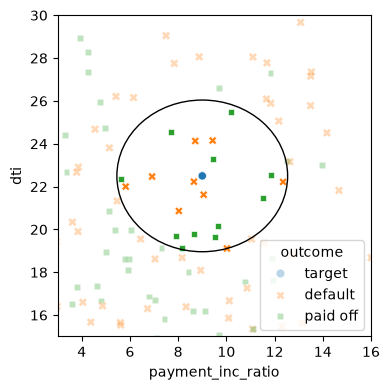

In [3]:
nbrs = knn.kneighbors(newloan)
maxDistance = np.max(nbrs[0][0])

fig, ax = plt.subplots(figsize=(4, 4))
sns.scatterplot(x='payment_inc_ratio', y='dti', style='outcome',
                hue='outcome', data=loan200, alpha=0.3, ax=ax)
sns.scatterplot(x='payment_inc_ratio', y='dti', style='outcome',
                hue='outcome',
                data=pd.concat([loan200.loc[0:0, :], loan200.loc[nbrs[1][0] + 1, :]]),
                ax=ax, legend=False)
ellipse = Ellipse(xy=newloan.values[0],
                  width=2 * maxDistance, height=2 * maxDistance,
                  edgecolor='black', fc='None', lw=1)
ax.add_patch(ellipse)
ax.set_xlim(3, 16)
ax.set_ylim(15, 30)

plt.tight_layout()
plt.show()

The highlighted points inside the circle are the 20 nearest neighbors of the new loan. The predicted class is simply the most common outcome among them.

### 1.2 Distance Metrics

Similarity (nearness) is determined using a **distance metric**:
- **Euclidean distance**: the straight-line distance between two points, the square root of the sum of squared differences. It is the most popular.
- **Manhattan distance**: the sum of absolute differences, like walking along city blocks.
- **Mahalanobis distance**: accounts for the correlation between variables, but is more expensive to compute.

### 1.3 One Hot Encoder

Categorical variables must be converted to numbers before distances can be calculated. **One hot encoding** creates a binary 0/1 variable for each category. Unlike in linear regression, all categories are usually kept in KNN, because multicollinearity is not a problem.

### 1.4 Standardization (Normalization, z-Scores)

Distance metrics are sensitive to the **scale** of the variables. A variable measured in large units (e.g., revolving balance in dollars) will dominate the distance calculation over variables measured in small units (e.g., ratios). **Standardization** (z-score) puts all variables on the same scale:

z = (x - mean) / standard deviation

The example below first finds the 5 nearest neighbors without standardization.

In [4]:
loan_data = pd.read_csv(LOAN_DATA_CSV)
loan_data = loan_data.drop(columns=['Unnamed: 0', 'status'])
loan_data['outcome'] = pd.Categorical(loan_data['outcome'],
                                      categories=['paid off', 'default'],
                                      ordered=True)

predictors = ['payment_inc_ratio', 'dti', 'revol_bal', 'revol_util']
outcome = 'outcome'

newloan = loan_data.loc[0:0, predictors]
print(newloan)

X = loan_data.loc[1:, predictors]
y = loan_data.loc[1:, outcome]

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X, y)

nbrs = knn.kneighbors(newloan)
print(X.iloc[nbrs[1][0], :])

   payment_inc_ratio  dti  revol_bal  revol_util
0             2.3932  1.0       1687         9.4
       payment_inc_ratio   dti  revol_bal  revol_util
35536            1.47212  1.46       1686        10.0
33651            3.38178  6.37       1688         8.4
25863            2.36303  1.39       1691         3.5
42953            1.28160  7.14       1684         3.9
43599            4.12244  8.98       1684         7.2


Without standardization, the neighbors are almost identical to the new loan in `revol_bal` but very different in the other variables. This is because `revol_bal` is measured in dollars and has much larger values, so it dominates the distance.

Below, the same search is done after standardizing all predictors.

In [5]:
newloan = loan_data.loc[0:0, predictors]
X = loan_data.loc[1:, predictors]
y = loan_data.loc[1:, outcome]

scaler = StandardScaler()
scaler.fit(X * 1.0)

X_std = scaler.transform(X * 1.0)
newloan_std = scaler.transform(newloan * 1.0)

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_std, y)

nbrs = knn.kneighbors(newloan_std)
print(X.iloc[nbrs[1][0], :])

       payment_inc_ratio   dti  revol_bal  revol_util
2080             2.61091  1.03       1218         9.7
1438             2.34343  0.51        278         9.9
30215            2.71200  1.34       1075         8.5
28542            2.39760  0.74       2917         7.4
44737            2.34309  1.37        488         7.2


After standardization, the neighbors are similar to the new loan across all four variables, which is a much more sensible result.

### 1.5 Choosing K

The choice of K is very important:
- If K is too small (e.g., 1), the model overfits: it captures noise in the data.
- If K is too large, the model oversmooths and may miss the local structure that makes KNN useful.

The best K is usually chosen by comparing accuracy on validation (holdout) data. Typical values are between 1 and 20, and an odd number is often used to avoid ties.

### 1.6 KNN as a Feature Engine

KNN can also be used to create new features for other models. Here, KNN is applied to several borrower credit variables, and its predicted probability is used as a single "borrower score" summarizing the credit history. This score can then be used as a predictor in another model.

['default' 'paid off']


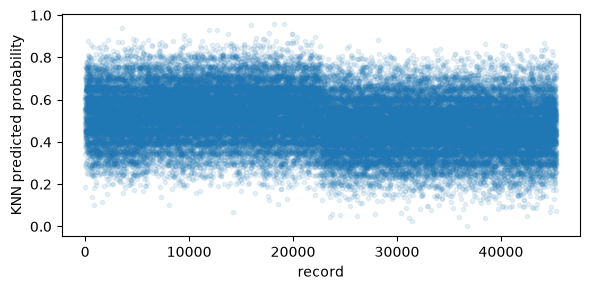

In [6]:
predictors = ['dti', 'revol_bal', 'revol_util', 'open_acc',
              'delinq_2yrs_zero', 'pub_rec_zero']
outcome = 'outcome'

X = loan_data[predictors]
y = loan_data[outcome]

knn = KNeighborsClassifier(n_neighbors=20)
knn.fit(X, y)
print(knn.classes_)

fig, ax = plt.subplots(figsize=(6, 3))
ax.scatter(range(len(X)),
           [bs + random.gauss(0, 0.015) for bs in knn.predict_proba(X)[:, 0]],
           alpha=0.1, marker='.')
ax.set_xlabel('record')
ax.set_ylabel('KNN predicted probability')
plt.tight_layout()
plt.show()

In [7]:
loan_data['borrower_score'] = knn.predict_proba(X)[:, 0]
loan_data['borrower_score'].describe()

count    45342.000000
mean         0.501091
std          0.128728
min          0.000000
25%          0.400000
50%          0.500000
75%          0.600000
max          0.950000
Name: borrower_score, dtype: float64

The KNN probabilities take a limited set of values (multiples of 1/20, since K = 20), which is why the plot shows horizontal bands (a little random noise was added to make them visible). The resulting `borrower_score` ranges from 0 to 1 and summarizes several credit variables into one feature.

## 2. Tree Models

**Tree models** (also called Classification and Regression Trees, CART, or decision trees) are a set of "if-then-else" rules that are easy to understand and implement. They can discover hidden patterns and interactions in the data that linear models would miss.

Key terms:
- **Recursive partitioning**: repeatedly dividing the data so that the outcomes in each final subdivision are as homogeneous as possible.
- **Split value**: a predictor value that divides the records into those where the predictor is less than the split value and those where it is greater.
- **Node**: in a decision tree, the graphical representation of a split rule.
- **Leaf**: the end of a set of if-then-else rules; the final node that gives the classification.
- **Loss**: the number of misclassifications at a stage in the splitting process.
- **Impurity**: the extent to which a mix of classes is found in a subpartition of the data. The more mixed, the more impure.
- **Pruning**: cutting back a fully grown tree to reduce overfitting.

### 2.1 A Simple Example

The example fits a tree to the `loan3000` data, predicting loan outcome from `borrower_score` and `payment_inc_ratio`.

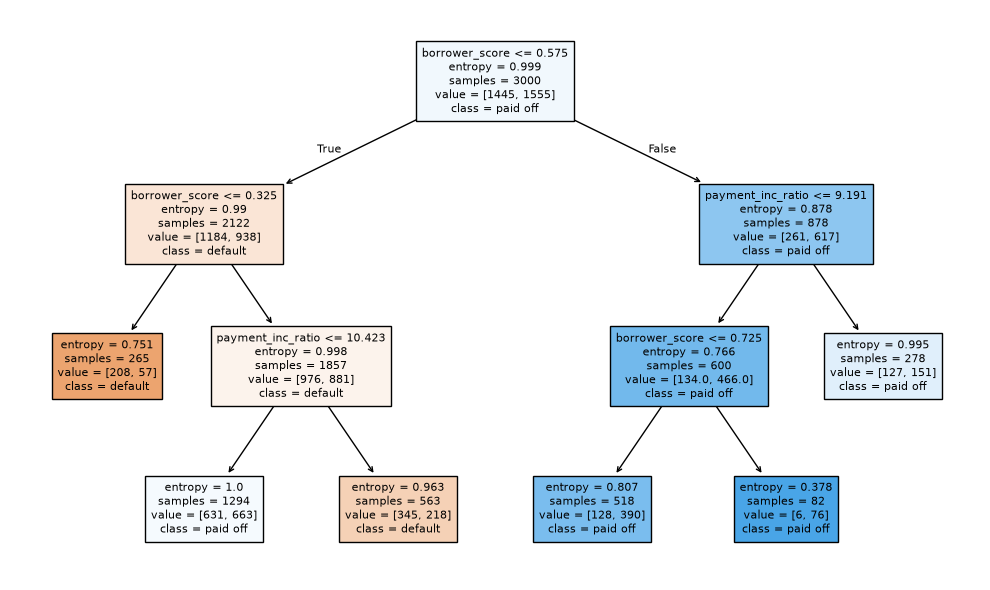

In [8]:
loan3000 = pd.read_csv(LOAN3000_CSV)

predictors = ['borrower_score', 'payment_inc_ratio']
outcome = 'outcome'

X = loan3000[predictors]
y = loan3000[outcome]

loan_tree = DecisionTreeClassifier(random_state=1, criterion='entropy',
                                   min_impurity_decrease=0.003)
loan_tree.fit(X, y)

fig, ax = plt.subplots(figsize=(10, 6))
plot_tree(loan_tree, feature_names=predictors, class_names=loan_tree.classes_,
          filled=True, ax=ax, fontsize=8)
plt.tight_layout()
plt.show()

In [9]:
print(export_text(loan_tree, feature_names=predictors))

|--- borrower_score <= 0.58
|   |--- borrower_score <= 0.33
|   |   |--- class: default
|   |--- borrower_score >  0.33
|   |   |--- payment_inc_ratio <= 10.42
|   |   |   |--- class: paid off
|   |   |--- payment_inc_ratio >  10.42
|   |   |   |--- class: default
|--- borrower_score >  0.58
|   |--- payment_inc_ratio <= 9.19
|   |   |--- borrower_score <= 0.72
|   |   |   |--- class: paid off
|   |   |--- borrower_score >  0.72
|   |   |   |--- class: paid off
|   |--- payment_inc_ratio >  9.19
|   |   |--- class: paid off



The tree first splits on `borrower_score`, and then refines the classification using further splits on both predictors. Each leaf gives a predicted class. The rules can be read directly, for example: if the borrower score is below a certain value and the payment-to-income ratio is high, predict default.

### 2.2 The Recursive Partitioning Algorithm

The algorithm works as follows:
1. Start with the full dataset.
2. For each predictor and each possible split value, divide the records into two groups and measure the homogeneity (purity) of the classes in each group.
3. Choose the split that gives the greatest within-group purity.
4. Repeat the process within each resulting group, until the groups are pure or a stopping rule is reached.

Each split divides the predictor space into rectangles, so the decision boundary of a tree is made of horizontal and vertical lines.

### 2.3 Measuring Homogeneity or Impurity

Three common impurity measures for a partition with proportion p of one class:
- **Accuracy / misclassification error**: not a good splitting criterion because it is not sensitive enough to changes in class proportions.
- **Gini impurity**: p(1 - p), summed across classes.
- **Entropy**: -p·log2(p) - (1 - p)·log2(1 - p).

The plot below compares the three measures (scaled) for a binary outcome.

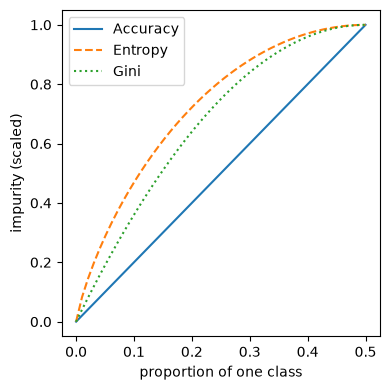

In [10]:
def entropyFunction(x):
    if x == 0:
        return 0
    return -x * math.log(x, 2) - (1 - x) * math.log(1 - x, 2)

def giniFunction(x):
    return x * (1 - x)

x = np.linspace(0, 0.5, 50)
impure = pd.DataFrame({
    'x': x,
    'Accuracy': 2 * x,
    'Gini': [giniFunction(xi) / giniFunction(.5) for xi in x],
    'Entropy': [entropyFunction(xi) for xi in x],
})

fig, ax = plt.subplots(figsize=(4, 4))
impure.plot(x='x', y='Accuracy', ax=ax, linestyle='solid')
impure.plot(x='x', y='Entropy', ax=ax, linestyle='--')
impure.plot(x='x', y='Gini', ax=ax, linestyle=':')
ax.set_xlabel('proportion of one class')
ax.set_ylabel('impurity (scaled)')

plt.tight_layout()
plt.show()

All three measures are 0 when a partition is pure and reach their maximum when the classes are equally mixed (p = 0.5). Gini and entropy are curved, so they reward splits that make partitions purer more strongly than accuracy does.

### 2.4 Stopping the Tree from Growing

A tree grown until every leaf is pure will overfit: it learns the noise in the training data. Ways to control tree growth:
- Avoid splitting a partition if it would create very small subpartitions (minimum node size).
- Do not split a partition if the improvement in impurity is too small (`min_impurity_decrease`).
- Limit the depth of the tree (`max_depth`).
- **Prune** the tree using a complexity parameter, chosen by cross-validation.

### 2.5 Predicting a Continuous Value

Trees can also predict a numeric outcome (**regression trees**). The splitting criterion is based on the squared deviation from the mean within each partition, and the prediction in each leaf is the average outcome of the records in it.

### 2.6 How Trees Are Used

Advantages of trees:
- They are easy to visualize and explain to non-technical audiences.
- They handle nonlinear relationships and interactions automatically.
- They require little data preparation (no standardization needed).

A single tree, however, is usually not the most accurate model. Its real power comes from combining many trees into ensembles, as in the next sections.

## 3. Bagging and the Random Forest

The **wisdom of crowds** idea applies to models too: averaging (or voting) the predictions of many models is usually more accurate than any single model. This is called an **ensemble**.

Key terms:
- **Ensemble**: forming a prediction by using a collection of models.
- **Bagging**: a general technique to form a collection of models by bootstrapping the data (bootstrap aggregating).
- **Random forest**: a type of bagged estimate based on decision tree models.
- **Variable importance**: a measure of the importance of a predictor in the performance of the model.

### 3.1 Bagging

Bagging works as follows:
1. Draw a bootstrap sample (with replacement) from the training data.
2. Fit a model to the bootstrap sample.
3. Repeat many times.
4. Average the predictions (or take a majority vote for classification).

### 3.2 Random Forest

The **random forest** applies bagging to decision trees with one important addition: at each split, only a **random subset of the predictors** is considered (typically about √p of the p predictors for classification). This makes the trees less correlated with each other, which makes the ensemble more accurate.

Records that are not in a tree's bootstrap sample are called **out-of-bag (OOB)** records. They can be used to estimate the model's error without needing a separate validation set.

In [11]:
predictors = ['borrower_score', 'payment_inc_ratio']
outcome = 'outcome'

X = loan3000[predictors]
y = loan3000[outcome]

rf = RandomForestClassifier(n_estimators=500, random_state=1, oob_score=True)
rf.fit(X, y)
print(rf.oob_decision_function_)

[[0.18131868 0.81868132]
 [0.26704545 0.73295455]
 [0.93333333 0.06666667]
 ...
 [1.         0.        ]
 [0.73157895 0.26842105]
 [0.68085106 0.31914894]]


`oob_decision_function_` gives, for each record, the proportion of trees (among those for which the record was out-of-bag) that voted for each class.

The plot below shows how the OOB accuracy changes as the number of trees increases. (A step size of 20 trees is used to keep the computation time reasonable.)

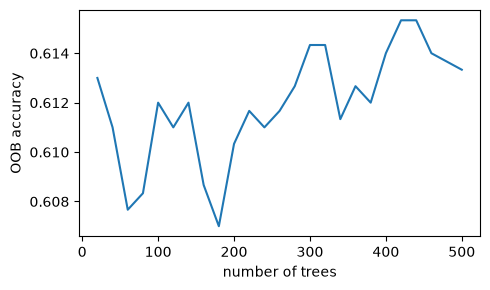

In [12]:
n_estimator = list(range(20, 510, 20))
oobScores = []
for n in n_estimator:
    rf = RandomForestClassifier(n_estimators=n, criterion='entropy',
                                max_depth=5, random_state=1, oob_score=True)
    rf.fit(X, y)
    oobScores.append(rf.oob_score_)

df = pd.DataFrame({'n': n_estimator, 'oobScore': oobScores})

fig, ax = plt.subplots(figsize=(5, 3))
df.plot(x='n', y='oobScore', ax=ax, legend=False)
ax.set_xlabel('number of trees')
ax.set_ylabel('OOB accuracy')
plt.tight_layout()
plt.show()

The OOB accuracy fluctuates when there are few trees and stabilizes as more trees are added. After a certain point, adding more trees does not improve the model much.

The plot below shows the predictions of the random forest.

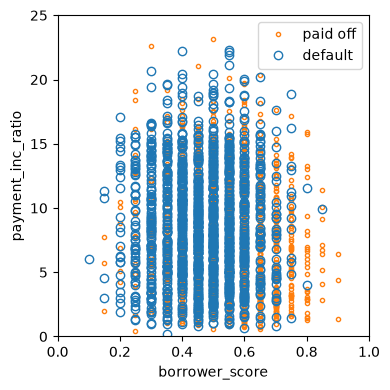

In [13]:
rf = RandomForestClassifier(n_estimators=500, random_state=1, oob_score=True)
rf.fit(X, y)

predictions = X.copy()
predictions['prediction'] = rf.predict(X)

fig, ax = plt.subplots(figsize=(4, 4))
predictions.loc[predictions.prediction == 'paid off'].plot(
    x='borrower_score', y='payment_inc_ratio', style='.',
    markerfacecolor='none', markeredgecolor='C1', ax=ax)
predictions.loc[predictions.prediction == 'default'].plot(
    x='borrower_score', y='payment_inc_ratio', style='o',
    markerfacecolor='none', markeredgecolor='C0', ax=ax)
ax.legend(['paid off', 'default'])
ax.set_xlim(0, 1)
ax.set_ylim(0, 25)
ax.set_xlabel('borrower_score')
ax.set_ylabel('payment_inc_ratio')

plt.tight_layout()
plt.show()

Unlike the smooth boundaries of LDA or logistic regression, the random forest boundary is irregular and patchy. The model is flexible enough to fit very local patterns, which also means it can overfit when there are only two predictors.

### 3.3 Variable Importance

Random forests can measure how important each predictor is. Two common measures:
- **Decrease in accuracy**: randomly permute the values of a variable and measure how much the model's accuracy drops. A large drop means the variable is important.
- **Decrease in node impurity (Gini or entropy)**: the total decrease in impurity from all splits on that variable, averaged over all trees. This is computed on the training data and is what scikit-learn returns as `feature_importances_`.

The example uses all relevant predictors in the loan data. These models take a while to fit.

In [14]:
predictors = ['loan_amnt', 'term', 'annual_inc', 'dti', 'payment_inc_ratio',
              'revol_bal', 'revol_util', 'purpose', 'delinq_2yrs_zero',
              'pub_rec_zero', 'open_acc', 'grade', 'emp_length', 'purpose_',
              'home_', 'emp_len_', 'borrower_score']
outcome = 'outcome'

X = pd.get_dummies(loan_data[predictors], drop_first=True, dtype=int)
y = loan_data[outcome]

rf_all = RandomForestClassifier(n_estimators=500, random_state=1, n_jobs=-1)
rf_all.fit(X, y)

rf_all_entropy = RandomForestClassifier(n_estimators=500, random_state=1,
                                        criterion='entropy', n_jobs=-1)
print(rf_all_entropy.fit(X, y))

RandomForestClassifier(criterion='entropy', n_estimators=500, n_jobs=-1,
                       random_state=1)


In [15]:
rf = RandomForestClassifier(n_estimators=100, random_state=1, n_jobs=-1)
scores = defaultdict(list)

# cross-validate the scores on a number of different random splits of the data
for split in range(3):
    train_X, valid_X, train_y, valid_y = train_test_split(X, y, test_size=0.3,
                                                          random_state=split)
    rf.fit(train_X, train_y)
    acc = accuracy_score(valid_y, rf.predict(valid_X))
    for column in X.columns:
        X_t = valid_X.copy()
        X_t[column] = np.random.permutation(X_t[column].values)
        shuff_acc = accuracy_score(valid_y, rf.predict(X_t))
        scores[column].append((acc - shuff_acc) / acc)

print('Features sorted by their score:')
print(sorted([(round(np.mean(score), 4), feat) for feat, score in scores.items()],
             reverse=True))

Features sorted by their score:
[(np.float64(0.077), 'borrower_score'), (np.float64(0.0433), 'grade'), (np.float64(0.0271), 'term_60 months'), (np.float64(0.0168), 'payment_inc_ratio'), (np.float64(0.0153), 'annual_inc'), (np.float64(0.0091), 'dti'), (np.float64(0.0034), 'open_acc'), (np.float64(0.0028), 'loan_amnt'), (np.float64(0.0026), 'revol_bal'), (np.float64(0.0021), 'revol_util'), (np.float64(0.002), 'purpose__small_business'), (np.float64(0.0017), 'home__OWN'), (np.float64(0.0016), 'purpose_credit_card'), (np.float64(0.0012), 'purpose_other'), (np.float64(0.0012), 'home__RENT'), (np.float64(0.0012), 'emp_length'), (np.float64(0.001), 'pub_rec_zero'), (np.float64(0.0009), 'purpose_small_business'), (np.float64(0.0007), 'purpose__other'), (np.float64(0.0005), 'purpose_debt_consolidation'), (np.float64(0.0005), 'purpose__home_improvement'), (np.float64(0.0003), 'purpose_wedding'), (np.float64(0.0003), 'purpose_house'), (np.float64(0.0002), 'purpose_home_improvement'), (np.float64(

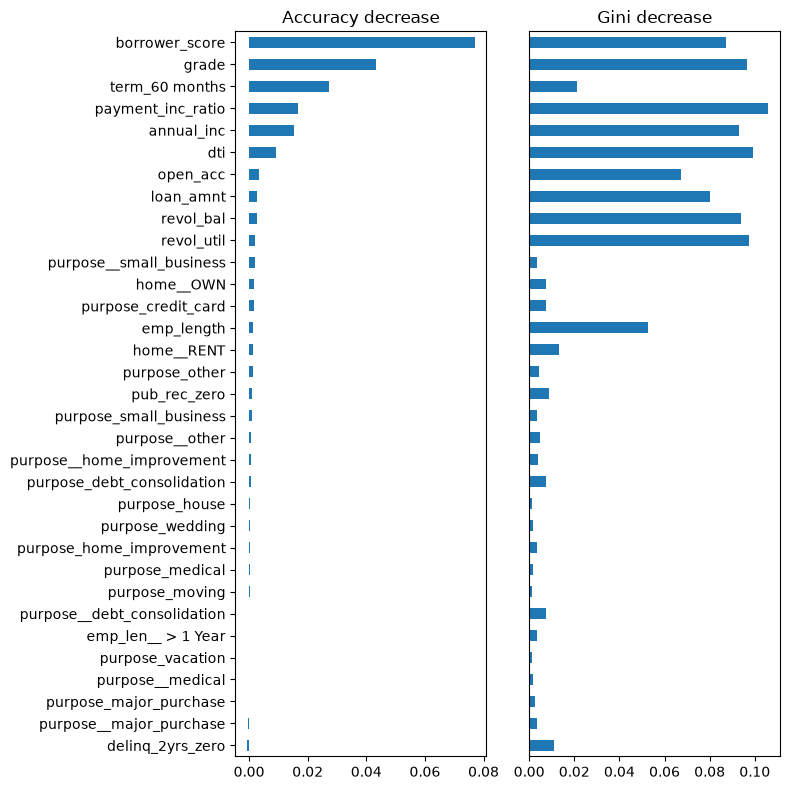

In [16]:
df = pd.DataFrame({
    'feature': X.columns,
    'Accuracy decrease': [np.mean(scores[column]) for column in X.columns],
    'Gini decrease': rf_all.feature_importances_,
    'Entropy decrease': rf_all_entropy.feature_importances_,
})
df = df.sort_values('Accuracy decrease')

fig, axes = plt.subplots(ncols=2, figsize=(8, 8))
ax = df.plot(kind='barh', x='feature', y='Accuracy decrease',
             legend=False, ax=axes[0])
ax.set_ylabel('')
ax.set_title('Accuracy decrease')

ax = df.plot(kind='barh', x='feature', y='Gini decrease',
             legend=False, ax=axes[1])
ax.set_ylabel('')
ax.set_title('Gini decrease')
ax.get_yaxis().set_visible(False)

plt.tight_layout()
plt.show()

Both measures agree that `borrower_score` and `payment_inc_ratio` are among the most important predictors. The two measures do not rank all variables the same way: the accuracy decrease is computed on validation data and is generally more reliable, while the Gini decrease is computed on training data and tends to favor continuous variables with many possible split values.

### 3.4 Hyperparameters

Random forests have **hyperparameters**: parameters that must be set before fitting the model and are not learned from the data. Important ones include:
- `n_estimators`: the number of trees.
- `max_features`: the number of predictors considered at each split.
- `min_samples_leaf` (node size): the minimum number of records in a leaf. Smaller values give larger, more complex trees.
- `max_leaf_nodes`: the maximum number of leaves in each tree.

Hyperparameters affect overfitting and are usually tuned using cross-validation.

## 4. Boosting

**Boosting** is another ensemble technique, but instead of fitting models independently, it fits a **series of models**, where each new model focuses on the records that the previous models got wrong.

Key terms:
- **Ensemble**: forming a prediction by using a collection of models.
- **Boosting**: a technique to fit a sequence of models, giving more weight to records with large residuals in each successive round.
- **AdaBoost**: an early version of boosting that reweights the data based on the residuals.
- **Gradient boosting**: a more general form of boosting that fits each new model to the residuals (gradient of the loss function) of the previous ones.
- **Stochastic gradient boosting**: gradient boosting that samples records and predictors at each round, which adds randomness and reduces overfitting.
- **Regularization**: a technique to avoid overfitting by adding a penalty term to the loss function based on the number of parameters or their size.
- **Hyperparameters**: parameters that need to be set before fitting the algorithm.

### 4.1 XGBoost

**XGBoost** is a popular and very efficient implementation of stochastic gradient boosting. Two important parameters are:
- `subsample`: the fraction of records sampled at each iteration (similar to the random sampling in random forests).
- `learning_rate` (eta): a shrinkage factor applied to each new tree, which slows down learning and helps prevent overfitting.

XGBoost requires a numeric outcome, so default is coded as 1 and paid off as 0.

In [17]:
predictors = ['borrower_score', 'payment_inc_ratio']
outcome = 'outcome'

X = loan3000[predictors]
y = pd.Series([1 if o == 'default' else 0 for o in loan3000[outcome]])

xgb = XGBClassifier(objective='binary:logistic', subsample=0.63,
                    eval_metric='error', random_state=1)
print(xgb.fit(X, y))

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='error', feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, ...)


In [18]:
xgb_df = X.copy()
xgb_df['prediction'] = ['default' if p == 1 else 'paid off' for p in xgb.predict(X)]
xgb_df['prob_default'] = xgb.predict_proba(X)[:, 1]
print(xgb_df.head())

   borrower_score  payment_inc_ratio prediction  prob_default
0            0.40            5.11135   paid off      0.324454
1            0.40            5.43165    default      0.708416
2            0.70            9.23003    default      0.525602
3            0.40            2.33482   paid off      0.367411
4            0.45           12.10320    default      0.943440


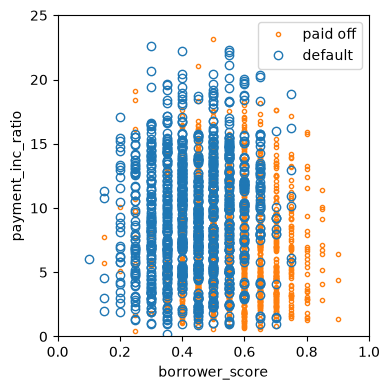

In [19]:
fig, ax = plt.subplots(figsize=(4, 4))
xgb_df.loc[xgb_df.prediction == 'paid off'].plot(
    x='borrower_score', y='payment_inc_ratio', style='.',
    markerfacecolor='none', markeredgecolor='C1', ax=ax)
xgb_df.loc[xgb_df.prediction == 'default'].plot(
    x='borrower_score', y='payment_inc_ratio', style='o',
    markerfacecolor='none', markeredgecolor='C0', ax=ax)
ax.legend(['paid off', 'default'])
ax.set_xlim(0, 1)
ax.set_ylim(0, 25)
ax.set_xlabel('borrower_score')
ax.set_ylabel('payment_inc_ratio')

plt.tight_layout()
plt.show()

The XGBoost predictions show a pattern similar to the random forest: borrowers with low scores and high payment-to-income ratios are predicted to default. The boundary is also somewhat irregular, which hints that the model may be fitting noise.

### 4.2 Regularization: Avoiding Overfitting

Using XGBoost blindly can lead to overfitting: very accurate on training data, much less accurate on new data. Regularization helps by penalizing model complexity:
- `reg_lambda` (L2 penalty) and `reg_alpha` (L1 penalty) shrink the weights of the trees.
- A smaller `learning_rate` and `subsample` < 1 also reduce overfitting.

The example below compares two models on the full loan data, using 10,000 records as a validation set:
- **default**: no penalty, a high learning rate (0.3), and no subsampling.
- **penalty**: a strong L2 penalty (`reg_lambda=1000`), a lower learning rate (0.1), and subsampling (0.63).

In [20]:
predictors = ['loan_amnt', 'term', 'annual_inc', 'dti', 'payment_inc_ratio',
              'revol_bal', 'revol_util', 'purpose', 'delinq_2yrs_zero',
              'pub_rec_zero', 'open_acc', 'grade', 'emp_length', 'purpose_',
              'home_', 'emp_len_', 'borrower_score']
outcome = 'outcome'

X = pd.get_dummies(loan_data[predictors], drop_first=True, dtype=int)
X.columns = [c.replace('<', 'lt').replace('[', '(').replace(']', ')')
             for c in X.columns]
y = pd.Series([1 if o == 'default' else 0 for o in loan_data[outcome]])

train_X, valid_X, train_y, valid_y = train_test_split(X, y, test_size=10000,
                                                      random_state=1)

xgb_default = XGBClassifier(objective='binary:logistic', n_estimators=250,
                            max_depth=6, reg_lambda=0, learning_rate=0.3,
                            subsample=1, random_state=1)
xgb_default.fit(train_X, train_y)

xgb_penalty = XGBClassifier(objective='binary:logistic', n_estimators=250,
                            max_depth=6, reg_lambda=1000, learning_rate=0.1,
                            subsample=0.63, random_state=1)
print(xgb_penalty.fit(train_X, train_y))

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.1, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=6,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=250,
              n_jobs=None, num_parallel_tree=None, ...)


In [21]:
pred_default = xgb_default.predict_proba(train_X)[:, 1]
error_default = abs(train_y - pred_default) > 0.5
print('default (train):', np.mean(error_default))

pred_default = xgb_default.predict_proba(valid_X)[:, 1]
error_default = abs(valid_y - pred_default) > 0.5
print('default (validation):', np.mean(error_default))

pred_penalty = xgb_penalty.predict_proba(valid_X)[:, 1]
error_penalty = abs(valid_y - pred_penalty) > 0.5
print('penalty (validation):', np.mean(error_penalty))

default (train): 0.10528549601041254
default (validation): 0.366
penalty (validation): 0.3289


The default model has a much lower error on the training data than on the validation data, which is a clear sign of overfitting. The penalized model has a lower validation error, meaning it generalizes better to new data.

The plot below shows how the training and validation errors change with the number of boosting iterations.

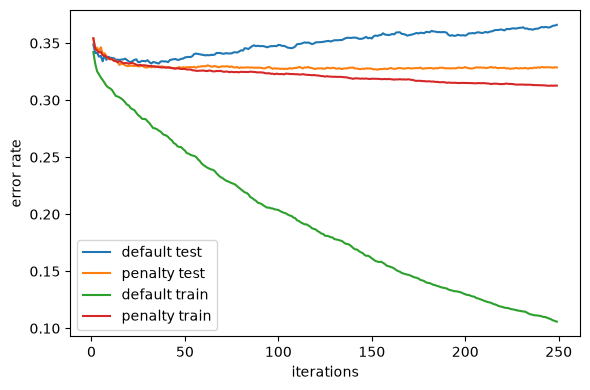

In [22]:
results = []
for i in range(1, 250):
    train_default = xgb_default.predict_proba(train_X, iteration_range=(0, i))[:, 1]
    train_penalty = xgb_penalty.predict_proba(train_X, iteration_range=(0, i))[:, 1]
    pred_default = xgb_default.predict_proba(valid_X, iteration_range=(0, i))[:, 1]
    pred_penalty = xgb_penalty.predict_proba(valid_X, iteration_range=(0, i))[:, 1]
    results.append({
        'iterations': i,
        'default train': np.mean(abs(train_y - train_default) > 0.5),
        'penalty train': np.mean(abs(train_y - train_penalty) > 0.5),
        'default test': np.mean(abs(valid_y - pred_default) > 0.5),
        'penalty test': np.mean(abs(valid_y - pred_penalty) > 0.5),
    })

results = pd.DataFrame(results)

fig, ax = plt.subplots(figsize=(6, 4))
results.plot(x='iterations', y='default test', ax=ax)
results.plot(x='iterations', y='penalty test', ax=ax)
results.plot(x='iterations', y='default train', ax=ax)
results.plot(x='iterations', y='penalty train', ax=ax)
ax.set_ylabel('error rate')

plt.tight_layout()
plt.show()

For the default model, the training error keeps decreasing with more iterations while the test error stops improving and starts to rise: the model is learning noise. For the penalized model, the training and test errors stay much closer together, which shows that regularization effectively controls overfitting.

### 4.3 Hyperparameters and Cross-Validation

XGBoost has many hyperparameters, and choosing them well is important. **Cross-validation** is the standard approach:
1. Randomly divide the data into K groups (folds).
2. For each fold, train the model on the other folds and evaluate it on the held-out fold.
3. Repeat for each combination of hyperparameters and compare the average error.

Below, 5-fold cross-validation is used to compare combinations of `learning_rate` (eta) and `max_depth`. This cell takes several minutes to run.

In [23]:
np.random.seed(1)
idx = np.random.choice(range(5), size=len(X), replace=True)

error = []
for eta, max_depth in product([0.1, 0.5, 0.9], [3, 6, 9]):
    xgb = XGBClassifier(objective='binary:logistic', n_estimators=250,
                        max_depth=max_depth, learning_rate=eta,
                        random_state=1, n_jobs=-1)
    cv_error = []
    for k in range(5):
        fold_idx = idx == k
        train_X = X.loc[~fold_idx]
        train_y = y[~fold_idx]
        valid_X = X.loc[fold_idx]
        valid_y = y[fold_idx]

        xgb.fit(train_X, train_y)
        pred = xgb.predict_proba(valid_X)[:, 1]
        cv_error.append(np.mean(abs(valid_y - pred) > 0.5))
    error.append({
        'eta': eta,
        'max_depth': max_depth,
        'avg_error': np.mean(cv_error),
    })
    print(error[-1])

errors = pd.DataFrame(error)
print(errors.pivot_table(index='eta', columns='max_depth', values='avg_error') * 100)

{'eta': 0.1, 'max_depth': 3, 'avg_error': np.float64(0.3296631854733902)}
{'eta': 0.1, 'max_depth': 6, 'avg_error': np.float64(0.33655080918731384)}
{'eta': 0.1, 'max_depth': 9, 'avg_error': np.float64(0.3469139227825141)}
{'eta': 0.5, 'max_depth': 3, 'avg_error': np.float64(0.34000715657406083)}
{'eta': 0.5, 'max_depth': 6, 'avg_error': np.float64(0.36667268999491565)}
{'eta': 0.5, 'max_depth': 9, 'avg_error': np.float64(0.37031035784794997)}
{'eta': 0.9, 'max_depth': 3, 'avg_error': np.float64(0.3532453822056301)}
{'eta': 0.9, 'max_depth': 6, 'avg_error': np.float64(0.38748640515484256)}
{'eta': 0.9, 'max_depth': 9, 'avg_error': np.float64(0.38316557087482755)}
max_depth          3          6          9
eta                                       
0.1        32.966319  33.655081  34.691392
0.5        34.000716  36.667269  37.031036
0.9        35.324538  38.748641  38.316557


The table shows the average cross-validated error (in percent) for each combination. In general, smaller learning rates and shallower trees give lower error, while large learning rates combined with deep trees overfit and perform worse. Cross-validation makes it possible to choose the best combination objectively instead of guessing.

## Summary

This chapter covers statistical machine learning methods that learn the structure of the data directly, without assuming a fixed model form.

Key takeaways:
- K-Nearest Neighbors classifies a record based on the classes of its most similar records. Predictors must be standardized so that variables on large scales do not dominate the distance, and K is chosen using validation data. KNN can also be used as a feature engine to create new predictors.
- Decision trees split the data recursively into increasingly homogeneous groups, producing easy-to-interpret rules. Impurity is measured with Gini or entropy, and tree growth must be controlled to avoid overfitting.
- Bagging combines many models fitted to bootstrap samples. Random forests add random selection of predictors at each split, and out-of-bag records provide a built-in error estimate.
- Variable importance shows which predictors contribute most to a model's performance, measured by the decrease in accuracy or in node impurity.
- Boosting fits a sequence of models, each focusing on the errors of the previous ones. XGBoost is a fast, powerful implementation of stochastic gradient boosting.
- Ensemble methods are prone to overfitting, so regularization (penalties, learning rate, subsampling) and hyperparameter tuning with cross-validation are essential.